# Módulo 55: Modelos autorregresivos AR(p)

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m55-modelos-ar.ipynb](m55-modelos-ar.ipynb). No es una tarea entregada del programa.

Un **modelo autorregresivo** pronostica cada valor de una serie a partir de sus propios valores pasados. Es el modelo de series de tiempo más sencillo que aprovecha la autocorrelación, y la base de los modelos ARIMA. En esta lección se simula un proceso AR(2) cuyos parámetros conocemos, para comprobar qué tan bien se recuperan y cómo se cuantifica la incertidumbre del pronóstico:

1. El modelo AR(p)
2. La condición de estacionariedad
3. La PACF y su corte en p
4. Estimación con `AutoReg`
5. Elegir p con AIC y BIC
6. División cronológica
7. Pronóstico multipaso con intervalos
8. Métricas: MSE y MAPE
9. Errores frecuentes
10. Ejercicio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

## 1. El modelo AR(p)

Un proceso **autorregresivo de orden p** cumple

$$y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \dots + \phi_p y_{t-p} + \varepsilon_t, \qquad \varepsilon_t \sim \text{ruido blanco}(0, \sigma^2).$$

Si es estacionario, su media es $\mu = c / (1 - \phi_1 - \dots - \phi_p)$. Se simulan 400 días de un AR(2) con $c = 20$, $\phi_1 = 0.5$, $\phi_2 = 0.3$ y $\sigma = 2$, cuya media es $20/(1 - 0.8) = 100$. Las primeras 100 observaciones se descartan para que la serie olvide su valor inicial.

Media muestral: 99.96   (teórica: 100)


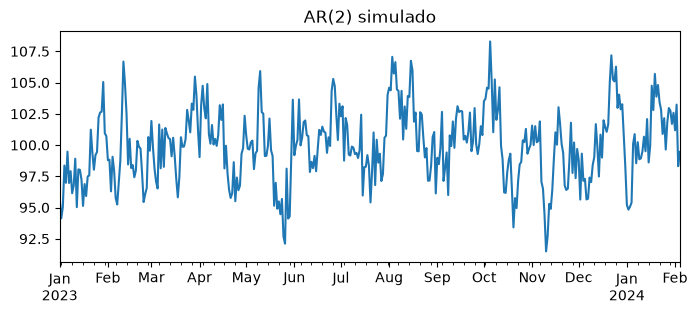

In [2]:
rng = np.random.default_rng(42)
c, phi1, phi2, sigma = 20.0, 0.5, 0.3, 2.0

n_total, descarte = 500, 100
y = np.full(n_total, 100.0)
for t in range(2, n_total):
    y[t] = c + phi1 * y[t - 1] + phi2 * y[t - 2] + rng.normal(0, sigma)

serie = pd.Series(y[descarte:], index=pd.date_range("2023-01-01", periods=n_total - descarte, freq="D"),
                  name="y")
print(f"Media muestral: {serie.mean():.2f}   (teórica: {c / (1 - phi1 - phi2):.0f})")

fig, ax = plt.subplots(figsize=(8, 3))
serie.plot(ax=ax, title="AR(2) simulado")
plt.show()

## 2. La condición de estacionariedad

Un AR(p) es estacionario si todas las raíces del **polinomio característico**

$$\Phi(z) = 1 - \phi_1 z - \phi_2 z^2 - \dots - \phi_p z^p$$

están **fuera del círculo unitario**, es decir, $\lvert z \rvert > 1$. Para un AR(1) equivale a $\lvert\phi_1\rvert < 1$. Para un AR(2), a las tres condiciones $\phi_1 + \phi_2 < 1$, $\phi_2 - \phi_1 < 1$ y $\lvert\phi_2\rvert < 1$. Si alguna raíz está en el círculo, la serie tiene raíz unitaria (como una caminata aleatoria); si está dentro, explota.

In [3]:
for f1, f2 in [(0.5, 0.3), (1.2, -0.4), (0.7, 0.5)]:
    raices = np.roots([-f2, -f1, 1])                    # coeficientes de Φ(z), de mayor a menor grado
    proceso = ArmaProcess(ar=[1, -f1, -f2], ma=[1])
    print(f"φ1={f1:>4}, φ2={f2:>4}: |raíces| = {np.abs(raices).round(3)}, estacionario: {proceso.isstationary}")

φ1= 0.5, φ2= 0.3: |raíces| = [2.84  1.174], estacionario: True
φ1= 1.2, φ2=-0.4: |raíces| = [1.581 1.581], estacionario: True
φ1= 0.7, φ2= 0.5: |raíces| = [2.278 0.878], estacionario: False


Con $\phi_1 = 1.2$ el proceso sigue siendo estacionario, porque lo que cuenta son las raíces y no cada coeficiente por separado (aquí son complejas, de módulo 1.58, y la serie oscila). Con $\phi_1 + \phi_2 = 1.2 > 1$, una raíz queda dentro del círculo y el proceso no es estacionario.

## 3. La PACF y su corte en p

La **autocorrelación parcial** de orden $k$ es la correlación entre $y_t$ e $y_{t-k}$ una vez descontado el efecto de los rezagos intermedios $y_{t-1}, \dots, y_{t-k+1}$. Coincide con el último coeficiente $\phi_{kk}$ de una regresión AR(k).

| Proceso | ACF | PACF |
| --- | --- | --- |
| AR(p) | Decae poco a poco | Se **corta** después del rezago p |

Por eso la PACF es la herramienta natural para proponer el orden de un AR.

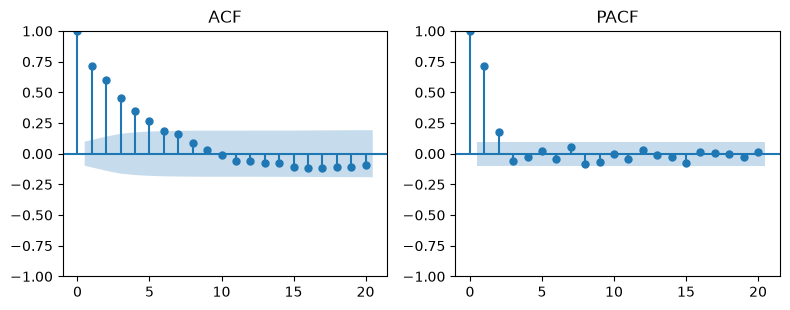

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
plot_acf(serie, lags=20, ax=axes[0], title="ACF")
plot_pacf(serie, lags=20, ax=axes[1], method="ywm", title="PACF")
plt.tight_layout()
plt.show()

La ACF decae poco a poco, mientras que la PACF tiene una barra grande en el rezago 1, otra más pequeña pero fuera de la banda en el rezago 2, y después queda dentro de la banda: la firma de un AR(2).

## 4. Estimación con `AutoReg`

`AutoReg(y, lags=p)` estima $c$ y los $\phi_i$ por mínimos cuadrados condicionales: una regresión de $y_t$ sobre sus $p$ rezagos. Las primeras $p$ observaciones no tienen rezagos completos y se pierden.

In [5]:
res_completo = AutoReg(serie, lags=2).fit()
print(pd.DataFrame({"estimado": res_completo.params, "real": [c, phi1, phi2]}).round(3))
print(f"σ estimada: {np.sqrt(res_completo.sigma2):.3f}   (real: {sigma})")

       estimado  real
const    23.524  20.0
y.L1      0.580   0.5
y.L2      0.185   0.3
σ estimada: 1.976   (real: 2.0)


Las estimaciones se acercan a los valores reales, con el error de muestreo esperable en 400 observaciones: $\hat\phi_2$ (0.19) se queda por debajo de 0.3, pero la suma $\hat\phi_1 + \hat\phi_2 = 0.77$, que determina la persistencia, está cerca de 0.8.

## 5. Elegir p con AIC y BIC

Con $k$ parámetros estimados, $n$ observaciones y log-verosimilitud $\ln L$:

$$\text{AIC} = -2\ln L + 2k, \qquad \text{BIC} = -2\ln L + k \ln n.$$

Se elige el p con menor criterio. Como $\ln n > 2$ para $n \ge 8$, el BIC castiga más cada parámetro y tiende a elegir modelos más pequeños. Dos precauciones:

- **Misma muestra.** Un AR(10) pierde 10 observaciones y un AR(1) solo una; para comparar con justicia, todos los órdenes deben ajustarse sobre las mismas observaciones. `ar_select_order` lo hace reservando las primeras `maxlag`.
- **El borde de la rejilla.** Si el p elegido es justo el máximo probado, el óptimo podría estar más allá: hay que ampliar la rejilla o preferir el BIC.

Aquí se usa toda la serie para ilustrar; en un análisis real, el orden se elige solo con los datos de entrenamiento.

In [6]:
for criterio in ["aic", "bic"]:
    sel = ar_select_order(serie, maxlag=12, ic=criterio)
    print(f"{criterio.upper()}: rezagos elegidos = {sel.ar_lags}")

# Rejilla demasiado corta: el óptimo queda en el borde
sel_corta = ar_select_order(serie, maxlag=1, ic="bic")
print(f"Con maxlag=1, el BIC elige {sel_corta.ar_lags}: está en el borde, hay que ampliar")

AIC: rezagos elegidos = [1, 2]
BIC: rezagos elegidos = [1, 2]
Con maxlag=1, el BIC elige [1]: está en el borde, hay que ampliar


## 6. División cronológica

En una serie de tiempo, el conjunto de prueba debe ser **posterior** al de entrenamiento. Mezclar las filas al azar permitiría que el modelo "viera" el futuro: los vecinos temporales de cada punto de prueba estarían en el entrenamiento. Se usan los primeros 320 días para entrenar y los últimos 80 para evaluar.

In [7]:
corte = 320
entrenamiento, prueba = serie.iloc[:corte], serie.iloc[corte:]
print("Entrenamiento:", entrenamiento.index.min().date(), "a", entrenamiento.index.max().date())
print("Prueba:       ", prueba.index.min().date(), "a", prueba.index.max().date())

res = AutoReg(entrenamiento, lags=2).fit()

Entrenamiento: 2023-01-01 a 2023-11-16
Prueba:        2023-11-17 a 2024-02-04


## 7. Pronóstico multipaso con intervalos

Para pronosticar $h$ pasos hacia adelante sin observar los valores intermedios, el modelo usa sus propios pronósticos como rezagos. El error se acumula: si $\psi_j$ son los coeficientes de la representación $y_t = \mu + \sum_{j \ge 0} \psi_j \varepsilon_{t-j}$ (con $\psi_0 = 1$), la varianza del error a $h$ pasos es

$$\operatorname{Var}(e_{t+h}) = \sigma^2 \sum_{j=0}^{h-1} \psi_j^2,$$

que crece con $h$ hasta la varianza total de la serie. `res.get_prediction(start, end).summary_frame(alpha=0.1)` devuelve el pronóstico y su intervalo al 90 %, que **se ensancha con el horizonte**. Una banda de ancho fijo $\pm z\,\hat\sigma_{res}$ solo es válida para un paso.

In [8]:
inicio, fin = len(entrenamiento), len(serie) - 1
marco = res.get_prediction(start=inicio, end=fin).summary_frame(alpha=0.10)
marco.index = prueba.index

z = stats.norm.ppf(0.95)
sd_res = res.resid.std()
banda_fija = pd.DataFrame({"inf": marco["mean"] - z * sd_res, "sup": marco["mean"] + z * sd_res})

semiancho = (marco["mean_ci_upper"] - marco["mean_ci_lower"]) / 2
print(f"Semiancho del intervalo del modelo: h=1 {semiancho.iloc[0]:.2f}, h=5 {semiancho.iloc[4]:.2f}, "
      f"h=80 {semiancho.iloc[-1]:.2f}")
print(f"Semiancho de la banda fija: {z * sd_res:.2f} en todos los horizontes")

dentro_modelo = ((prueba >= marco["mean_ci_lower"]) & (prueba <= marco["mean_ci_upper"])).mean()
dentro_fija = ((prueba >= banda_fija["inf"]) & (prueba <= banda_fija["sup"])).mean()
print(f"Cobertura en prueba: intervalo del modelo {dentro_modelo:.0%}, banda fija {dentro_fija:.0%} (nominal 90 %)")

Semiancho del intervalo del modelo: h=1 3.28, h=5 4.48, h=80 4.69
Semiancho de la banda fija: 3.28 en todos los horizontes
Cobertura en prueba: intervalo del modelo 86%, banda fija 72% (nominal 90 %)


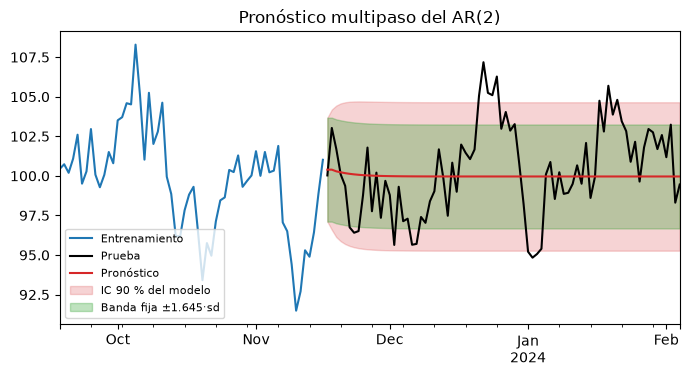

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
entrenamiento.iloc[-60:].plot(ax=ax, label="Entrenamiento")
prueba.plot(ax=ax, label="Prueba", color="k")
marco["mean"].plot(ax=ax, label="Pronóstico", color="C3")
ax.fill_between(marco.index, marco["mean_ci_lower"], marco["mean_ci_upper"],
                color="C3", alpha=0.2, label="IC 90 % del modelo")
ax.fill_between(marco.index, banda_fija["inf"], banda_fija["sup"],
                color="C2", alpha=0.3, label="Banda fija ±1.645·sd")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Pronóstico multipaso del AR(2)")
plt.show()

El pronóstico converge rápido a la media del proceso, y el intervalo del modelo se ensancha hasta estabilizarse en la variabilidad total de la serie. La banda fija solo refleja el error de un paso, por lo que deja fuera a muchas observaciones: subestima la incertidumbre.

## 8. Métricas: MSE y MAPE

$$\text{MSE} = \frac1n \sum_t (y_t - \hat y_t)^2, \qquad \text{MAPE} = \frac{100}{n} \sum_t \left\lvert \frac{y_t - \hat y_t}{y_t} \right\rvert.$$

El MAPE se expresa en porcentaje y no tiene unidades, pero solo es interpretable si la serie se mantiene lejos de 0. Conviene distinguir el pronóstico **multipaso** (todo el período de prueba desde el último dato de entrenamiento) del pronóstico **a un paso** (cada día con los valores reales del día anterior), que siempre es más preciso.

In [10]:
const, f1_hat, f2_hat = res.params
un_paso = const + f1_hat * serie.shift(1) + f2_hat * serie.shift(2)    # usa los valores reales
un_paso = un_paso.loc[prueba.index]

def mse(real, pred):
    return np.mean((real - pred) ** 2)

def mape(real, pred):
    return 100 * np.mean(np.abs((real - pred) / real))

print(f"Multipaso: MSE={mse(prueba, marco['mean']):.2f}  MAPE={mape(prueba, marco['mean']):.2f} %")
print(f"Un paso:   MSE={mse(prueba, un_paso):.2f}  MAPE={mape(prueba, un_paso):.2f} %")

Multipaso: MSE=8.47  MAPE=2.36 %
Un paso:   MSE=3.64  MAPE=1.53 %


## 9. Errores frecuentes

**Mezclar las observaciones al dividir.** `train_test_split` baraja por defecto. En series de tiempo se divide por fecha, o con `shuffle=False`.

**Usar una banda de ancho constante para un pronóstico de varios pasos.** Como se vio en la sección 7, subestima la incertidumbre. Los intervalos deben salir del modelo (`get_prediction(...).conf_int(alpha=...)` o `summary_frame`).

**Aceptar un p en el borde de la rejilla.** Si el criterio elige el máximo probado, no hay evidencia de que sea el mejor: puede ser mejor uno mayor. Hay que ampliar la rejilla y, con pocas observaciones, preferir el BIC.

**Calcular el MAPE con valores cercanos a cero.** Un solo valor pequeño en el denominador domina el promedio:

In [11]:
real = np.array([10.0, 12.0, 0.1, 11.0])
pred = np.array([11.0, 11.0, 1.0, 10.0])
print(f"MAE: {np.mean(np.abs(real - pred)):.2f}   MAPE: {mape(real, pred):.1f} %")

MAE: 0.97   MAPE: 231.9 %


Todos los errores son de alrededor de una unidad, pero el valor 0.1 dispara el MAPE.

## 10. Ejercicio

Simula 300 meses de un AR(1) con $c = 10$, $\phi = 0.8$ y $\sigma = 3$, empezando en su media:

```python
rng = np.random.default_rng(42)
y = np.full(300, 50.0)
for t in range(1, 300):
    y[t] = 10 + 0.8 * y[t - 1] + rng.normal(0, 3)
meses = pd.Series(y, index=pd.date_range("2000-01-01", periods=300, freq="MS"))
```

1. ¿Es estacionario? ¿Cuál es su media teórica?
2. Usa los últimos 24 meses como prueba. Con el entrenamiento, elige el orden con el BIC y `maxlag=8`. ¿Queda en el borde? ¿Coincide con el proceso real?
3. Ajusta un AR(1) y un AR con el orden elegido, y compara el MSE y el MAPE de sus pronósticos multipaso en prueba.
4. Con el AR(1), pronostica los 24 meses con intervalos al 90 % y compara el semiancho a 1 y 24 pasos con la fórmula teórica: $\operatorname{Var}(e_{t+h}) = \sigma^2 \frac{1 - \phi^{2h}}{1 - \phi^2}$.

### Solución

In [12]:
rng = np.random.default_rng(42)
y1 = np.full(300, 50.0)
for t in range(1, 300):
    y1[t] = 10 + 0.8 * y1[t - 1] + rng.normal(0, 3)
meses = pd.Series(y1, index=pd.date_range("2000-01-01", periods=300, freq="MS"))

# 1. |φ| < 1: estacionario, con media 10 / (1 - 0.8) = 50
print("Estacionario:", ArmaProcess(ar=[1, -0.8], ma=[1]).isstationary, " media teórica:", round(10 / (1 - 0.8), 2))

# 2. División cronológica y orden por BIC con el entrenamiento
m_tr, m_te = meses.iloc[:-24], meses.iloc[-24:]
rezagos_bic = ar_select_order(m_tr, maxlag=8, ic="bic").ar_lags
print("BIC elige los rezagos:", rezagos_bic)

# 3. AR(1) frente al orden elegido
ajustes = {}
for p in sorted({1, len(rezagos_bic)}):
    ajustes[p] = AutoReg(m_tr, lags=p).fit()
    pron = ajustes[p].predict(start=len(m_tr), end=len(meses) - 1).to_numpy()
    print(f"AR({p}): MSE={mse(m_te.to_numpy(), pron):.2f}  "
          f"MAPE={mape(m_te.to_numpy(), pron):.2f} %")

Estacionario: True  media teórica: 50.0
BIC elige los rezagos: [1, 2]
AR(1): MSE=7.13  MAPE=4.58 %
AR(2): MSE=7.19  MAPE=4.48 %


In [13]:
# 4. Intervalos del AR(1) frente a la fórmula teórica
r1 = ajustes[1]
mf = r1.get_prediction(start=len(m_tr), end=len(meses) - 1).summary_frame(alpha=0.10)
semi = (mf["mean_ci_upper"] - mf["mean_ci_lower"]) / 2
phi_hat, s_hat = r1.params.iloc[1], np.sqrt(r1.sigma2)
for h in [1, 24]:
    teorico = stats.norm.ppf(0.95) * s_hat * np.sqrt((1 - phi_hat ** (2 * h)) / (1 - phi_hat ** 2))
    print(f"h={h:>2}: semiancho del modelo={semi.iloc[h - 1]:.3f}, fórmula={teorico:.3f}")

h= 1: semiancho del modelo=4.581, fórmula=4.581
h=24: semiancho del modelo=7.298, fórmula=7.298


El BIC elige dos rezagos aunque el proceso real es un AR(1): en esta muestra concreta, el ruido simulado deja una autocorrelación parcial en el rezago 2 que el criterio considera real. No está en el borde de la rejilla (máximo 8), así que no hace falta ampliarla. En la prueba, los dos modelos pronostican con errores parecidos. El intervalo del AR(1) coincide con la fórmula teórica evaluada con los parámetros estimados: a 1 paso depende solo de $\sigma$, y a 24 pasos se acerca a la desviación total de la serie, $\sigma/\sqrt{1 - \phi^2}$.

## Resumen

- Un AR(p) explica $y_t$ con sus p rezagos; es estacionario si las raíces de $1 - \phi_1 z - \dots - \phi_p z^p$ están fuera del círculo unitario.
- La PACF de un AR(p) se corta después del rezago p, y `AutoReg` estima los coeficientes por mínimos cuadrados.
- El orden se elige con AIC o BIC sobre una muestra común; si el elegido está en el borde de la rejilla, hay que ampliarla, y con pocas observaciones conviene el BIC.
- La división es cronológica, y los intervalos de un pronóstico multipaso, obtenidos del modelo, crecen con el horizonte; una banda fija subestima la incertidumbre.
- El MSE y el MAPE resumen el error de pronóstico; el MAPE falla con valores cercanos a 0.

En el **Módulo 56** se amplía la familia con la diferenciación y las medias móviles: los modelos ARIMA.